# Energy Consumption Data Analysis`
Dataset:** `Energy_Consumption_PowerBI_Ready.csv`  
**Important:** Crime-specific fields (City, Crime Domain, Victim Age, Case Closed, etc.) are replaced with energy-specific columns. The original notebook's MySQL connection is optional; this notebook works directly from the CSV.

## 1. Database Connection 
The original notebook loads its data from MySQL. The cells below show an optional connection pattern; skip them unless you have created a database/table and configured your own credentials. Never share database passwords in notebooks.

In [70]:
!pip install pandas

Defaulting to user installation because normal site-packages is not writeable


In [71]:
!pip install pandas openpyxl sqlalchemy pymysql

Defaulting to user installation because normal site-packages is not writeable


In [72]:
import pandas as pd
from sqlalchemy import create_engine, text

In [73]:
file_path = r"Energy_Consumption.xlsx"

df = pd.read_excel(r"C:\Users\ashis\Downloads\Energy_Consumption.xlsx")
display(df.head())

,Date,Building,Water Consumption,Electricity Consumption,Gas Consumption
0,2016-01-01,B1000,346159,38819,3378
1,2016-01-01,B1001,281717,46252,2187
2,2016-01-01,B1002,259530,41091,3173
3,2016-01-01,B1003,309176,25577,3581
4,2016-01-01,B1004,257742,33917,4709


In [74]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Connect to MySQL server
server_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="pri123",
    host="localhost",
    port=3306
)

server_engine = create_engine(server_url)

# Create the database
with server_engine.begin() as connection:
    connection.execute(text("CREATE DATABASE IF NOT EXISTS energy_db"))

print("Database created successfully!")

Database created successfully!


In [75]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="pri123",
    host="localhost",
    port=3306,
    database="energy_db"
)

engine = create_engine(db_url)

print("Connected to MySQL successfully!")

Connected to MySQL successfully!


In [76]:
with engine.connect() as connection:
    result = connection.execute(text("SELECT VERSION()"))
    print("MySQL Version:", result.scalar())

MySQL Version: 8.0.46


In [77]:
import pandas as pd

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# MySQL connection
db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="pri123",
    host="localhost",
    port=3306,
    database="energy_db"
)

engine = create_engine(db_url)

# Test the connection
with engine.connect() as connection:
    print("Connected to MySQL successfully!")

Connected to MySQL successfully!


## 2. Importing Libraries

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 3. Loading the Dataset

In [79]:
file_path = Path("Energy_Consumption.xlsx")
if not file_path.exists():
    # Helpful fallback for this notebook's original working environment
    file_path = Path(r"C:\Users\ashis\Downloads\Energy_Consumption.xlsx")

df = pd.read_excel("Energy_Consumption.xlsx")
df.columns = df.columns.str.replace("\ufeff", "", regex=False).str.strip()
df.head()

,Date,Building,Water Consumption,Electricity Consumption,Gas Consumption
0,2016-01-01,B1000,346159,38819,3378
1,2016-01-01,B1001,281717,46252,2187
2,2016-01-01,B1002,259530,41091,3173
3,2016-01-01,B1003,309176,25577,3581
4,2016-01-01,B1004,257742,33917,4709


## 4. Checking the Last Rows

In [80]:
df.tail(4)

,Date,Building,Water Consumption,Electricity Consumption,Gas Consumption
524,2019-12-01,B1007,319388,37106,4748
525,2019-12-01,B1008,251866,47079,5909
526,2019-12-01,B1009,280510,48134,5492
527,2019-12-01,B1010,443282,42027,5610


## 5. Checking the Shape of the Dataset

In [81]:
print("Rows, columns:", df.shape)

Rows, columns: (528, 5)


## 6. Checking the Column Names

In [82]:
print(df.columns.tolist())

['Date', 'Building', 'Water Consumption', 'Electricity Consumption', 'Gas Consumption']


## 7. Checking Data Types and Non-Null Counts

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 528 entries, 0 to 527
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     528 non-null    datetime64[ns]
 1   Building                 528 non-null    object        
 2   Water Consumption        528 non-null    int64         
 3   Electricity Consumption  528 non-null    int64         
 4   Gas Consumption          528 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 20.8+ KB


## 8. Checking Missing Values

In [84]:
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values

Date                       0
Building                   0
Water Consumption          0
Electricity Consumption    0
Gas Consumption            0
dtype: int64

## 9. Handling Missing Values (if any)
The crime notebook filled a categorical field with a label. This dataset is numeric/time-based, so missing values are handled by column type: numeric columns with their median, and categorical columns with their mode. No values are changed when there are no missing values.

In [85]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

for col in numeric_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isna().any():
        mode_values = df[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Not Specified"
        df[col] = df[col].fillna(fill_value)

print("Missing values remaining:", int(df.isnull().sum().sum()))

Missing values remaining: 0


## 10. Converting `Date` to Datetime

In [92]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Invalid/missing dates after conversion:", df["Date"].isna().sum())
df[["Date"]].head()

Invalid/missing dates after conversion: 0


,Date
0,2016-01-01
1,2016-01-01
2,2016-01-01
3,2016-01-01
4,2016-01-01


## 12. Creating / Verifying Time Features

In [94]:
df["Year"] = df["Date"].dt.year
df["Month Number"] = df["Date"].dt.month
df["Month"] = df["Date"].dt.strftime("%b")
df["Day"] = df["Date"].dt.day

In [95]:
# 1. Automatically find all columns with 'Zone' in their name
zone_cols = [col for col in df.columns if 'Zone' in col]
print("Found columns:", zone_cols)

# 2. Calculate the total power consumption using the found columns
df["Total Power Consumption"] = df[zone_cols].sum(axis=1)

# 3. View the result
df[["Date", "Year", "Month", "Day", "Total Power Consumption"]].head()

Found columns: []


,Date,Year,Month,Day,Total Power Consumption
0,2016-01-01,2016,Jan,1,0.0
1,2016-01-01,2016,Jan,1,0.0
2,2016-01-01,2016,Jan,1,0.0
3,2016-01-01,2016,Jan,1,0.0
4,2016-01-01,2016,Jan,1,0.0


## 11. Checking if the Dates and Time Fields Are Consistent

In [96]:
print("Rows with invalid dates:", df["Date"].isna().sum())
print("Rows with month number outside 1–12:", (~df["Month Number"].between(1, 12)).sum())
print("Rows where Year disagrees with Date:", (df["Year"] != df["Date"].dt.year).sum())

Rows with invalid dates: 0
Rows with month number outside 1–12: 0
Rows where Year disagrees with Date: 0


In [97]:
print(df.columns.tolist())

['Date', 'Building', 'Water Consumption', 'Electricity Consumption', 'Gas Consumption', 'Total Power Consumption', 'Year', 'Month Number', 'Month', 'Day']


In [98]:
# Sum Electricity and Gas consumption (or include 'Water Consumption' if required for your analysis)
consumption_cols = ['Electricity Consumption', 'Gas Consumption']

df['Total Power Consumption'] = df[consumption_cols].sum(axis=1)

df[['Date', 'Year', 'Month', 'Day', 'Total Power Consumption']].head()

,Date,Year,Month,Day,Total Power Consumption
0,2016-01-01,2016,Jan,1,42197
1,2016-01-01,2016,Jan,1,48439
2,2016-01-01,2016,Jan,1,44264
3,2016-01-01,2016,Jan,1,29158
4,2016-01-01,2016,Jan,1,38626


In [99]:
df["Year"] = df["Date"].dt.year
df["Month Number"] = df["Date"].dt.month
df["Month"] = df["Date"].dt.strftime("%b")
df["Day"] = df["Date"].dt.day

# Sum your dataset's actual power columns
df["Total Power Consumption"] = df[
    ["Electricity Consumption", "Gas Consumption"]
].sum(axis=1)

df[["Date", "Year", "Month", "Day", "Total Power Consumption"]].head()

,Date,Year,Month,Day,Total Power Consumption
0,2016-01-01,2016,Jan,1,42197
1,2016-01-01,2016,Jan,1,48439
2,2016-01-01,2016,Jan,1,44264
3,2016-01-01,2016,Jan,1,29158
4,2016-01-01,2016,Jan,1,38626


## 13. Summary Statistics of the Dataset

In [100]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,528,2017-12-15 23:00:00,2016-01-01 00:00:00,2016-12-24 06:00:00,2017-12-16 12:00:00,2018-12-08 18:00:00,2019-12-01 00:00:00,NaN
Water Consumption,528.0,352737.361742,202733.0,271849.75,348379.0,429888.25,505757.0,90883.262407
Electricity Consumption,528.0,41035.943182,21445.0,33845.5,41085.0,48677.25,59522.0,9199.54625
Gas Consumption,528.0,4835.393939,2149.0,4074.5,4851.5,5590.5,7351.0,1137.674361
Total Power Consumption,528.0,45871.337121,25247.0,38512.5,45626.0,53505.5,66112.0,9469.357204
Year,528.0,2017.5,2016.0,2016.75,2017.5,2018.25,2019.0,1.119094
Month Number,528.0,6.5,1.0,3.75,6.5,9.25,12.0,3.455326
Day,528.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0


## 14. Boxplots to Check Outliers

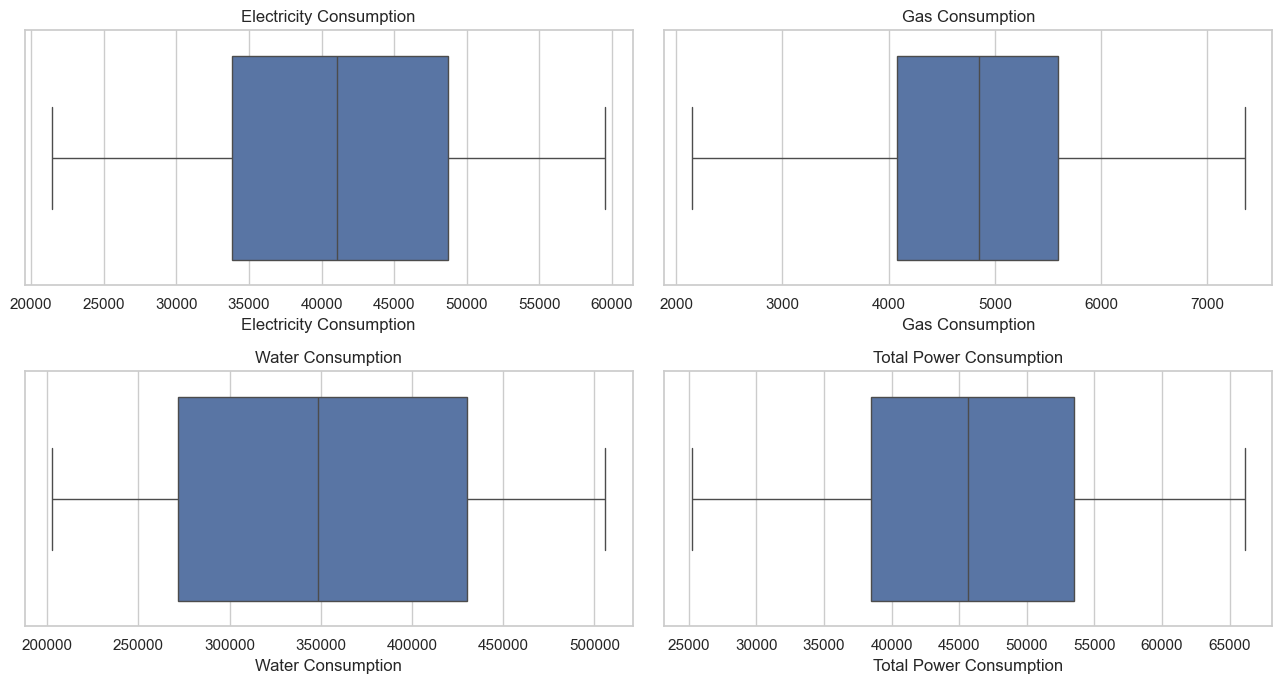

In [101]:
consumption_cols = [
    "Electricity Consumption",
    "Gas Consumption",
    "Water Consumption",
    "Total Power Consumption"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 7))

for col, ax in zip(consumption_cols, axes.flatten()):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 15. Chart 1: Top 10 Dates by Total Power Consumption

In [102]:
top_dates = df.groupby("Date")["Total Power Consumption"].sum().sort_values(ascending=False).head(10)
top_dates

Date
2019-09-01    612294
2019-03-01    601472
2018-10-01    578984
2019-08-01    574679
2019-11-01    572219
2018-11-01    569838
2018-07-01    566445
2017-09-01    561147
2019-05-01    558911
2018-04-01    554933
Name: Total Power Consumption, dtype: int64

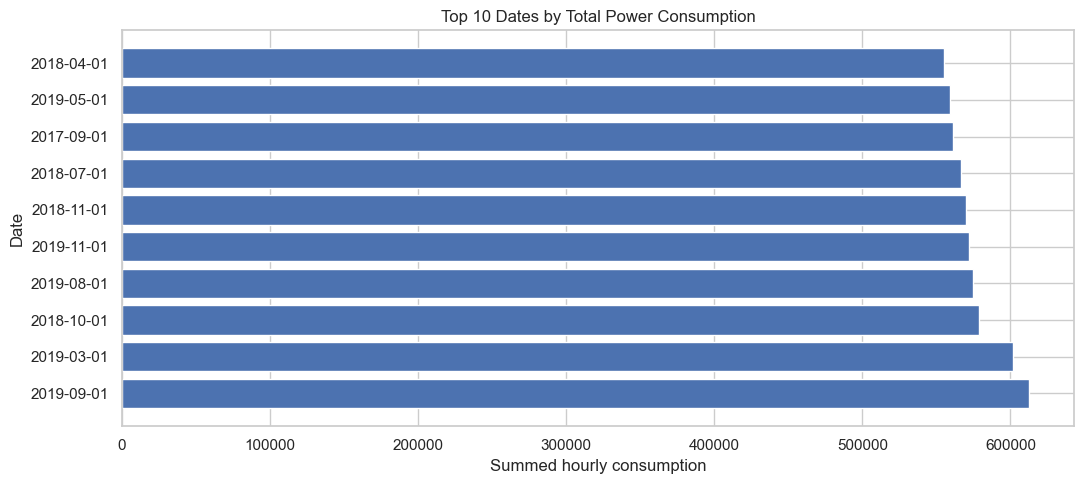

In [103]:
plt.figure(figsize=(11, 5))
plt.barh(top_dates.index.astype(str), top_dates.values)
plt.title("Top 10 Dates by Total Power Consumption")
plt.xlabel("Summed hourly consumption")
plt.ylabel("Date")
plt.tight_layout()
plt.show()

## 16. Chart 2: Power Consumption Share by Zone

In [104]:
consumption_totals = df[["Electricity Consumption", "Gas Consumption", "Water Consumption"]].sum()
consumption_totals

Electricity Consumption     21666978
Gas Consumption              2553088
Water Consumption          186245327
dtype: int64

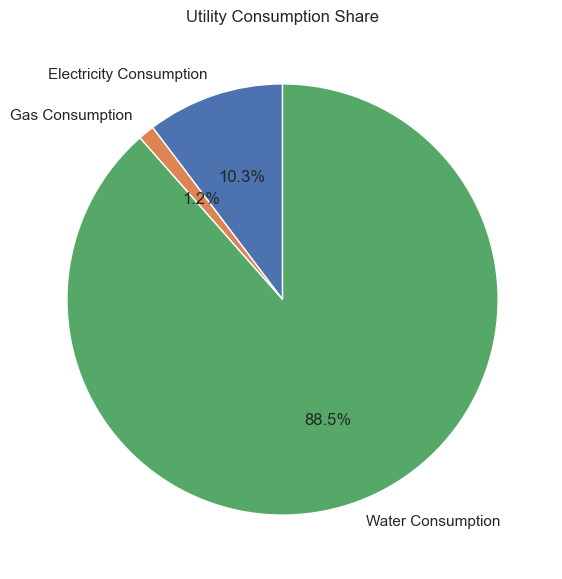

In [105]:
plt.figure(figsize=(7, 7))
plt.pie(
    consumption_totals.values,
    labels=consumption_totals.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Utility Consumption Share")
plt.show()

## 17. Chart 3: Average Consumption by Zone

In [106]:
zone_means = df[
    ["Electricity Consumption", "Gas Consumption", "Water Consumption"]
].mean().sort_values(ascending=False)

zone_means

Water Consumption          352737.361742
Electricity Consumption     41035.943182
Gas Consumption              4835.393939
dtype: float64

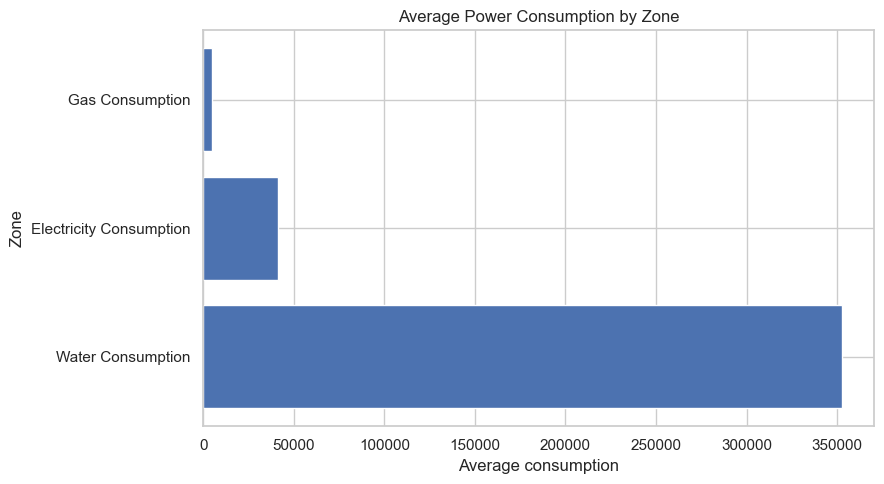

In [107]:
plt.figure(figsize=(9, 5))
plt.barh(zone_means.index, zone_means.values)
plt.title("Average Power Consumption by Zone")
plt.xlabel("Average consumption")
plt.ylabel("Zone")
plt.tight_layout()
plt.show()

## 18. Chart 4: Total Power Consumption by Year

In [108]:
yearly_consumption = df.groupby("Year")["Total Power Consumption"].sum().sort_index()
yearly_consumption

Year
2016    5438523
2017    5839295
2018    6286516
2019    6655732
Name: Total Power Consumption, dtype: int64

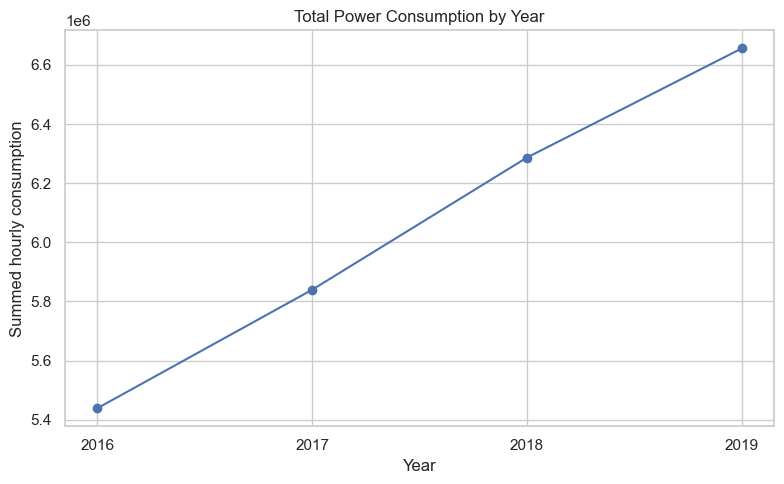

In [109]:
plt.figure(figsize=(8, 5))
plt.plot(yearly_consumption.index, yearly_consumption.values, marker="o")
plt.xticks(yearly_consumption.index)
plt.title("Total Power Consumption by Year")
plt.xlabel("Year")
plt.ylabel("Summed hourly consumption")
plt.tight_layout()
plt.show()

## 19. Chart 5: Average Consumption by Month

In [110]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_consumption = df.groupby("Month Number")["Total Power Consumption"].mean().reindex(range(1, 13))
monthly_consumption.index = month_order[:len(monthly_consumption)]
monthly_consumption

Jan    42712.431818
Feb    45399.727273
Mar    45049.818182
Apr    45970.295455
May    44678.431818
Jun    45873.250000
Jul    44522.931818
Aug    46303.909091
Sep    47865.045455
Oct    48243.045455
Nov    47826.272727
Dec    46010.886364
Name: Total Power Consumption, dtype: float64

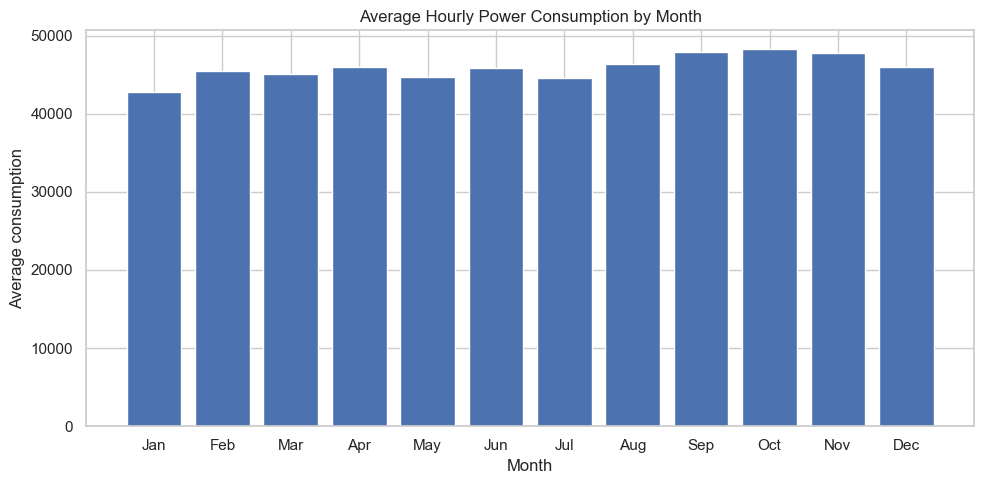

In [111]:
plt.figure(figsize=(10, 5))
plt.bar(monthly_consumption.index, monthly_consumption.values)
plt.title("Average Hourly Power Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average consumption")
plt.tight_layout()
plt.show()

## 20. Chart 6: Average Consumption by Day

In [112]:
hourly_consumption = df.groupby("Day")["Total Power Consumption"].mean().sort_index()
hourly_consumption

Day
1    45871.337121
Name: Total Power Consumption, dtype: float64

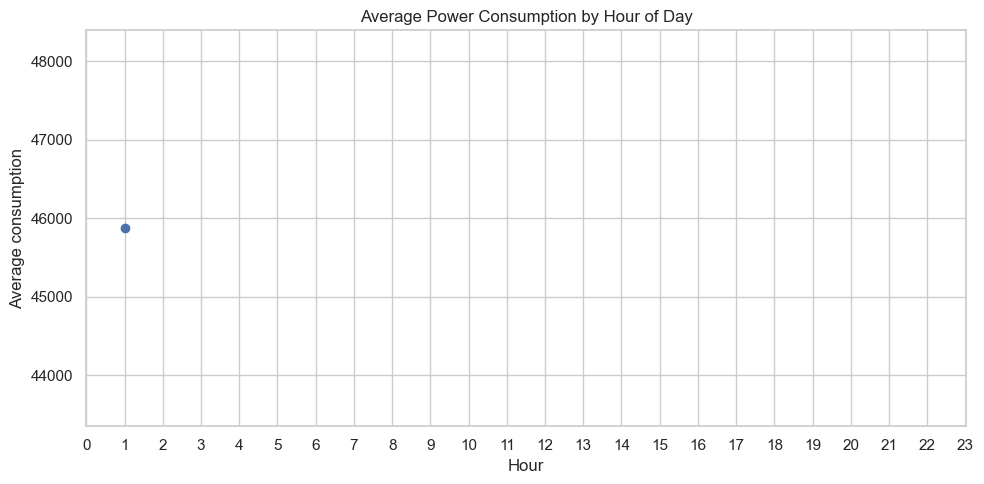

In [113]:
plt.figure(figsize=(10, 5))
plt.plot(hourly_consumption.index, hourly_consumption.values, marker="o")
plt.xticks(range(0, 24))
plt.title("Average Power Consumption by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average consumption")
plt.tight_layout()
plt.show()

## 21. Chart 7: Temperature vs Total Power Consumption

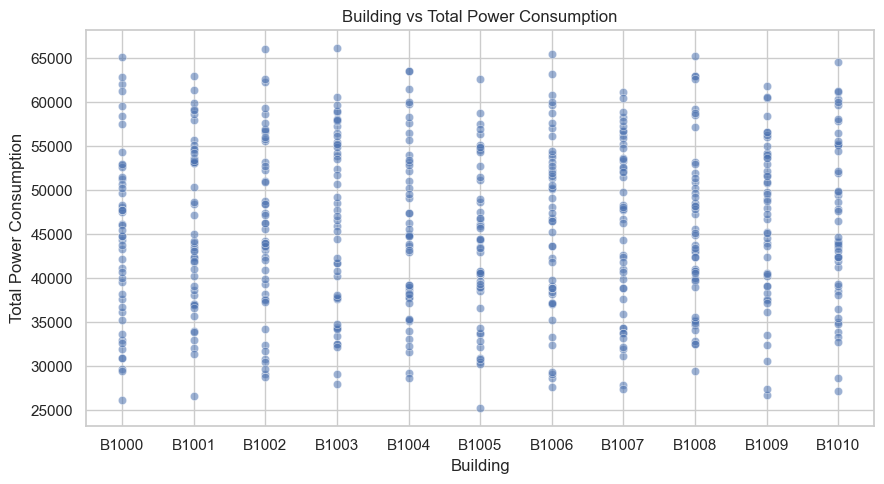

In [114]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Building", y="Total Power Consumption", alpha=0.55)
plt.title("Building vs Total Power Consumption")
plt.tight_layout()
plt.show()

## 22. Chart 8: Correlation Heatmap

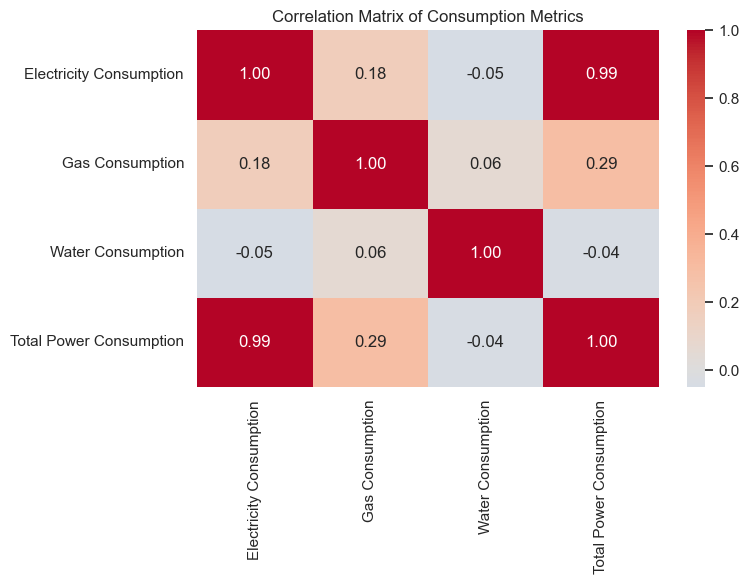

In [115]:
correlation_cols = [
    "Electricity Consumption",
    "Gas Consumption",
    "Water Consumption",
    "Total Power Consumption"
]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[correlation_cols].corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Consumption Metrics")
plt.tight_layout()
plt.show()

## 23. Interactive Plotly Chart

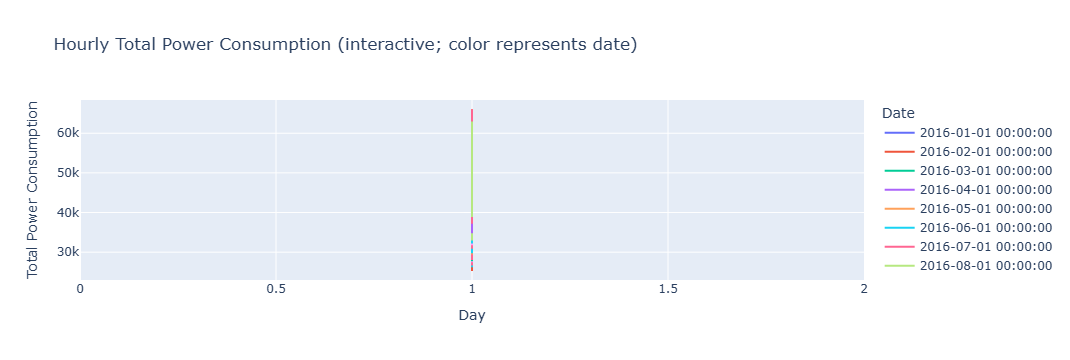

In [116]:
fig = px.line(
    df.sort_values(["Date", "Day"]),
    x="Day",
    y="Total Power Consumption",
    color="Date",
    title="Hourly Total Power Consumption (interactive; color represents date)",
    labels={"Hour": "Hour of Day", "Total Power Consumption": "Total Power Consumption"}
)
fig.show()

## 24. SQL-Style Grouped Analysis (Pandas Equivalent)

In [117]:
# Equivalent of: SELECT Year, SUM(total consumption) ... GROUP BY Year ORDER BY ...
year_summary = (
    df.groupby("Year", as_index=False)
      .agg(
          Total_Consumption=("Total Power Consumption", "sum"),
          Average_Hourly_Consumption=("Total Power Consumption", "mean"),
          Maximum_Hourly_Consumption=("Total Power Consumption", "max"),
          Records=("Total Power Consumption", "size")
      )
      .sort_values("Year")
)
year_summary

,Year,Total_Consumption,Average_Hourly_Consumption,Maximum_Hourly_Consumption,Records
0,2016,5438523,41200.931818,56612,132
1,2017,5839295,44237.083333,59215,132
2,2018,6286516,47625.121212,63589,132
3,2019,6655732,50422.212121,66112,132


## 25. Final Dataset Check

In [118]:
print("Final shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", int(df.isnull().sum().sum()))
df.head()

Final shape: (528, 10)
Duplicate rows: 0
Missing values: 0


,Date,Building,Water Consumption,Electricity Consumption,Gas Consumption,Total Power Consumption,Year,Month Number,Month,Day
0,2016-01-01,B1000,346159,38819,3378,42197,2016,1,Jan,1
1,2016-01-01,B1001,281717,46252,2187,48439,2016,1,Jan,1
2,2016-01-01,B1002,259530,41091,3173,44264,2016,1,Jan,1
3,2016-01-01,B1003,309176,25577,3581,29158,2016,1,Jan,1
4,2016-01-01,B1004,257742,33917,4709,38626,2016,1,Jan,1


## 26. Key Takeaways
Use the outputs above to identify the highest-consumption periods, compare zones, understand hourly/monthly patterns, and inspect relationships between weather and consumption. Correlation does not by itself establish causation.